<a href="https://colab.research.google.com/github/potopinc/colab/blob/main/ML_12_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Описание датасета Wine


Датасет Wine содержит результаты химического анализа трёх различных сортов вина,
произведённых из одного и того же винограда, но принадлежащих к разным производителям.
Задача классификации — определить сорт вина (класс 0, 1 или 2) на основе химических характеристик.

Целевая переменная:
- **Wine**: тип вина (0, 1, 2)

Признаки:
- **Alcohol** — содержание алкоголя (%).
- **Malic.acid** — содержание яблочной кислоты.
- **Ash** — содержание золы.
- **Acl (Alkalinity of ash)** — щелочность золы.
- **Mg (Magnesium)** — содержание магния.
- **Phenols (Total phenols)** — общее количество фенольных соединений.
- **Flavanoids** — содержание флавоноидов.
- **Nonflavanoid.phenols** — содержание нефлавоноидных фенолов.
- **Proanth (Proanthocyanins)** — содержание проантоцианов.
- **Color.int (Color intensity)** — интенсивность цвета.
- **Hue** — оттенок вина.
- **OD** — отношение оптической плотности на разных длинах волн.
- **Proline** — содержание аминокислоты пролина.

# Импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler

# Загрузка данных

In [ ]:
df = pd.read_csv('wine.csv')
df

,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
168,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
169,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
170,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [ ]:
y = df['Wine']
X = df.drop(columns = ['Wine'])

# Задания

#### **Задание 1**

1.1. Построй график распределения классов.

1.2. Какой процент данных следует отдать на Test?

1.3. Какую метрику здесь лучше использоать: `accuracy` или `f1`. Почему?

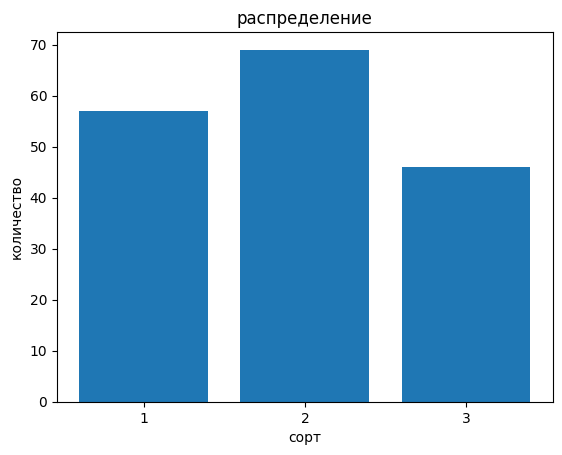

In [ ]:
#1.1
c = y.value_counts().sort_index()
plt.bar(c.index.astype(str), c.values)
plt.xlabel('сорт')
plt.ylabel('количество')
plt.title('распределение')
plt.show()

Ответ на 1.2: 25% чтобы осталось больше процентов для обучения

Ответ на 1.3: f1 тк если третий класс имеет очень маленький объем, следовательно модель может ошибаться чаще если использовать accuracy

#### **Задание 2**

Используя кросс-валидацию, найди значение метрики `accuracy` и `f1` для `KNN`.

Параметр `cv = 4` (количество фолдов).

Используй `scoring = 'accuracy'` или `scoring = 'f1_macro'`.

In [21]:
knn = KNeighborsClassifier()
acc = cross_val_score(knn, X, y, cv = 4, scoring='accuracy')
f1 = cross_val_score(knn, X, y, cv = 4, scoring='f1_macro')
print(acc.round(2), acc.mean().round(2))
print(f1.round(2), f1.mean().round(2))

[0.67 0.72 0.74 0.72] 0.72
[0.65 0.72 0.74 0.68] 0.7


#### **Задание 3**

Построй графики зависимости оценки качества от кол-ва соседей (1−86):

*   accuracy
*   f1_score


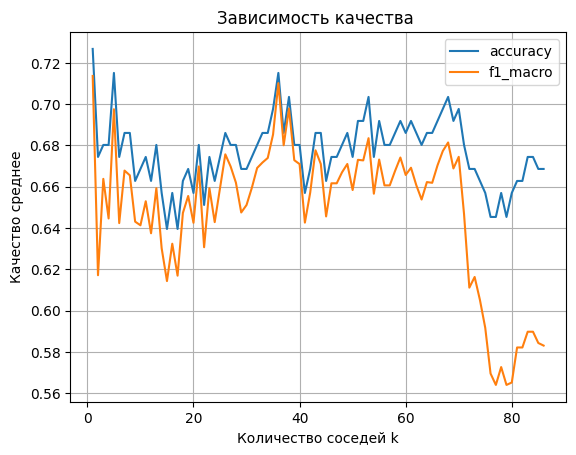

In [25]:
ks = range(1, 87)

acc_list = []
f1_list = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    acc_list.append(cross_val_score(knn, X, y, cv=4, scoring='accuracy').mean())
    f1_list.append(cross_val_score(knn, X, y, cv=4, scoring='f1_macro').mean())


plt.plot(ks, acc_list, label='accuracy')
plt.plot(ks, f1_list, label='f1_macro')
plt.xlabel('Количество соседей k')
plt.ylabel('Качество среднее')
plt.title('Зависимость качества ')
plt.legend()
plt.grid(True)
plt.show()

#### **Задание 4**

Повтори задание 2, но на этот раз учитывай расстояние до соседей при определении метки класса.

In [26]:
knn_d = KNeighborsClassifier(weights='distance')

acc_d = cross_val_score(knn_d, X, y, cv=4, scoring='accuracy')
f1_d  = cross_val_score(knn_d, X, y, cv=4, scoring='f1_macro')

print(acc_d.round(2), acc_d.mean().round(3))
print(f1_d.round(2),  f1_d.mean().round(3))

[0.7  0.67 0.65 0.79] 0.703
[0.68 0.68 0.65 0.76] 0.695


#### **Задание 5**

Добавь к графику из задания 3 ещё один график, который отображает те же данные, но с учётом расстояния.


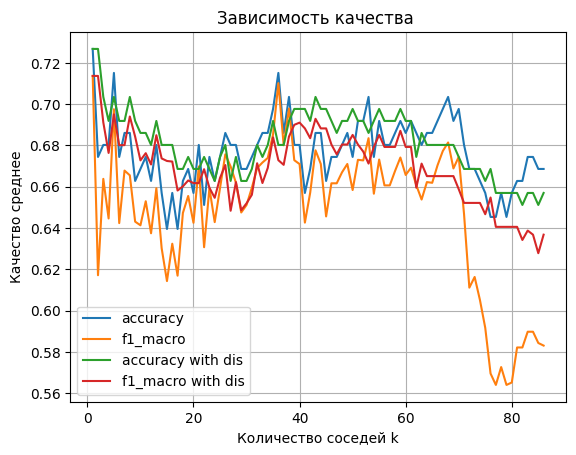

In [28]:
ks = range(1, 87)

acc_list = []
f1_list = []

acc_list_ = []
f1_list_ = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn_ = KNeighborsClassifier(n_neighbors=k, weights='distance')

    acc_list.append(cross_val_score(knn, X, y, cv=4, scoring='accuracy').mean())
    f1_list.append(cross_val_score(knn, X, y, cv=4, scoring='f1_macro').mean())

    acc_list_.append(cross_val_score(knn_, X, y, cv=4, scoring='accuracy').mean())
    f1_list_.append(cross_val_score(knn_, X, y, cv=4, scoring='f1_macro').mean())


plt.plot(ks, acc_list, label='accuracy')
plt.plot(ks, f1_list, label='f1_macro')
plt.plot(ks, acc_list_, label='accuracy with dis')
plt.plot(ks, f1_list_, label='f1_macro with dis')
plt.xlabel('Количество соседей k')
plt.ylabel('Качество среднее')
plt.title('Зависимость качества ')
plt.legend()
plt.grid(True)
plt.show()

#### **Задание 6**

Отмасштабируй данные с помощью Sklearn.

Повторно выполни задание 2 для измененного набора данных.

In [29]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

knn = KNeighborsClassifier()
acc_s = cross_val_score(knn, X_scaled, y, cv=4, scoring='accuracy')
f1_s  = cross_val_score(knn, X_scaled, y, cv=4, scoring='f1_macro')

print(acc_s.round(2), acc_s.mean().round(3))
print(f1_s.round(2),  f1_s.mean().round(3))

[0.95 0.98 0.98 0.95] 0.965
[0.96 0.98 0.98 0.95] 0.966


#### **Задание 7**
Выбери только ту метрику (accuracy или f1), которую ты указал в задании 1.

Построй на одном графике 4 функции:

- метрика без учёта расстояния (задание 3);
- метрика с учётом расстояния (задание 5);
- метрика на масштабированных данных без учёта расстояния;
- метрика на масштабированных данных с учётом расстояния.

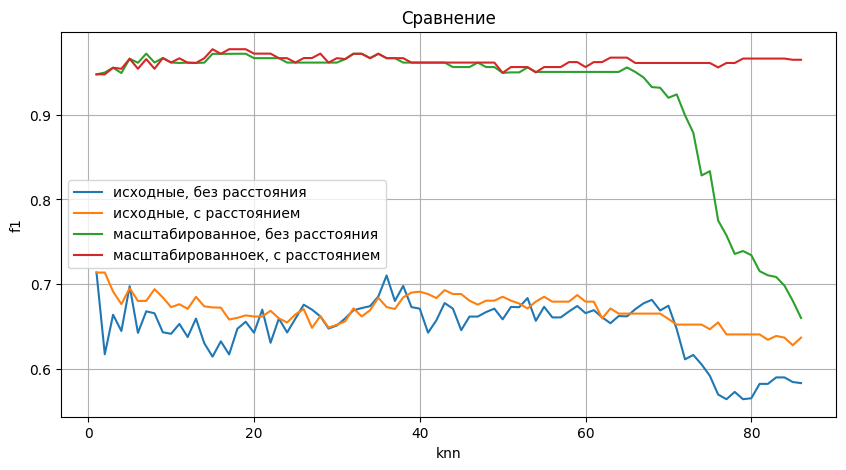

In [31]:
f1_list_s = []
f1_list_sd = []
for k in ks:
    knn_s  = KNeighborsClassifier(n_neighbors=k)
    knn_sd = KNeighborsClassifier(n_neighbors=k, weights='distance')
    f1_list_s.append(cross_val_score(knn_s,  X_scaled, y, cv=4, scoring='f1_macro').mean())
    f1_list_sd.append(cross_val_score(knn_sd, X_scaled, y, cv=4, scoring='f1_macro').mean())

plt.figure(figsize=(10, 5))
plt.plot(ks, f1_list,    label='исходные, без расстояния')
plt.plot(ks, f1_list_,   label='исходные, с расстоянием')
plt.plot(ks, f1_list_s,  label='масштабированное, без расстояния')
plt.plot(ks, f1_list_sd, label='масштабированноек, с расстоянием')
plt.xlabel('knn')
plt.ylabel('f1')
plt.title('Сравнение')
plt.legend()
plt.grid(True)
plt.show()

#### **Задание 8**

Для лучшей модели из задания 7 определи, какой тип подсчета расстояния лучше:

- `euclidean`
- `manhattan`
- `chebyshev`

Построй график сравнения.

#### **Задание 9***

Используй все доступные инструменты улучшения модели:
- параметры KNeighborsClassifier;
- виды масштабирования.

Получи наилучшее качество.

В ответе укажи комбинацию параметров и вид масштабирования, а также наилучшее значение метрики `f1_score`.